In [ ]:
!pip install -q sentence-transformers datasets evaluate scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.7 MB/s eta 0:00:00


In [ ]:
import os
os.environ["WANDB_DISABLED"] = "true"

import torch
import numpy as np
import pandas as pd
from datasets import load_dataset
from sentence_transformers import SentenceTransformer, InputExample, losses, evaluation
from sentence_transformers import models
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

from google.colab import drive
drive.mount('/content/drive')

Device: cuda
Mounted at /content/drive


In [ ]:
print("Loading dataset from HuggingFace: mferdian/aes_essay_dataset ...")
raw_ds = load_dataset("mferdian/aes_essay_dataset")

for split in raw_ds.keys():
    print(f"Split {split} columns:", raw_ds[split].column_names)

cols_to_keep = ["question", "reference_answer", "answer", "score"]
dataset = raw_ds.map(
    lambda x: {col: x[col] for col in cols_to_keep},
    remove_columns=[col for col in raw_ds["train"].column_names if col not in cols_to_keep]
)

print(dataset)


Loading dataset from HuggingFace: mferdian/aes_essay_dataset ...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/128 [00:00<?, ?B/s]

training.csv: 0.00B [00:00, ?B/s]

validation.csv: 0.00B [00:00, ?B/s]

...

Split train columns: ['question', 'reference_answer', 'answer', 'score']
Split validation columns: ['question', 'reference_answer', 'answer', 'score']
Split test columns: ['question', 'reference_answer', 'answer', 'score']


Map:   0%|          | 0/30000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10290 [00:00<?, ? examples/s]

✅ Dataset cleaned!
DatasetDict({
    train: Dataset({
        features: ['question', 'reference_answer', 'answer', 'score'],
        num_rows: 30000
    })
    validation: Dataset({
        features: ['question', 'reference_answer', 'answer', 'score'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['question', 'reference_answer', 'answer', 'score'],
        num_rows: 10290
    })
})


In [ ]:
def normalize_score(score):
    if score is None:
        return 0.0
    return max(0.0, min(1.0, float(score) / 100.0))

def make_input_examples(dataset_split, include_question=False, max_samples=None):
    examples = []
    it = dataset_split
    if max_samples:
        it = dataset_split.select(range(min(max_samples, len(dataset_split))))
    for item in tqdm(it, desc="Creating InputExamples"):
        ref = item.get("reference_answer", "") or ""
        ans = item.get("answer", "") or ""
        q   = item.get("question", "") or ""
        if include_question:
            s1 = f"Q: {q} Ref: {ref}"
        else:
            s1 = ref
        s2 = ans
        label = normalize_score(item.get("score", 0.0))
        examples.append(InputExample(texts=[s1, s2], label=label))
    return examples

train_split = dataset["train"]
valid_split = dataset["validation"] if "validation" in dataset else dataset["train"].select(range(int(len(train_split)*0.1)))
test_split  = dataset["test"] if "test" in dataset else valid_split

include_question = False
train_examples = make_input_examples(train_split, include_question=include_question)
val_examples   = make_input_examples(valid_split, include_question=include_question)
test_examples  = make_input_examples(test_split, include_question=include_question)

print(f"Train examples: {len(train_examples)} | Val: {len(val_examples)} | Test: {len(test_examples)}")

Creating InputExamples:   0%|          | 0/30000 [00:00<?, ?it/s]

Creating InputExamples:   0%|          | 0/5000 [00:00<?, ?it/s]

Creating InputExamples:   0%|          | 0/10290 [00:00<?, ?it/s]

Train examples: 30000 | Val: 5000 | Test: 10290


In [ ]:
BASE_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
print("Loading base model:", BASE_MODEL)
model = SentenceTransformer(BASE_MODEL)
model.to(device)
print("Embedding dimension:", model.get_sentence_embedding_dimension())

Loading base model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding dimension: 384


In [ ]:
train_batch_size = 16
train_dataloader = DataLoader(train_examples, shuffle=True, batch_size=train_batch_size)
train_loss = losses.CosineSimilarityLoss(model=model)

val_sentences1 = [ex.texts[0] for ex in val_examples]
val_sentences2 = [ex.texts[1] for ex in val_examples]
val_labels     = [ex.label for ex in val_examples]
evaluator = evaluation.EmbeddingSimilarityEvaluator(val_sentences1, val_sentences2, val_labels, name="val-eval")

num_epochs = 4
warmup_steps = max(100, int(len(train_dataloader) * num_epochs * 0.1))
output_path = "/content/drive/MyDrive/sbert_essay_model"
os.makedirs(output_path, exist_ok=True)

print(f"Training for {num_epochs} epochs, warmup_steps={warmup_steps}, output -> {output_path}")

Training for 4 epochs, warmup_steps=750, output -> /content/drive/MyDrive/sbert_essay_model


In [ ]:
model.fit(
    train_objectives=[(train_dataloader, train_loss)],
    evaluator=evaluator,
    epochs=num_epochs,
    evaluation_steps=500,
    warmup_steps=warmup_steps,
    output_path=output_path,
    show_progress_bar=True
)

Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).
Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss,Validation Loss,Val-eval Pearson Cosine,Val-eval Spearman Cosine
500,0.026900,No log,0.789791,0.754629
1000,0.011900,No log,0.808289,0.802222
1500,0.011300,No log,0.805280,0.792746
1875,0.011300,No log,0.805427,0.805155
2000,0.011000,No log,0.810084,0.810517
2500,0.010400,No log,0.787998,0.780582
3000,0.010500,No log,0.798820,0.799235
3500,0.010300,No log,0.806373,0.816820
3750,0.010300,No log,0.818980,0.826676
4000,0.009800,No log,0.822440,0.827795


Evaluating:   0%|          | 0/10290 [00:00<?, ?it/s]

✅ Test MSE: 0.0524 | MAE: 0.1839 | R2: 0.1529


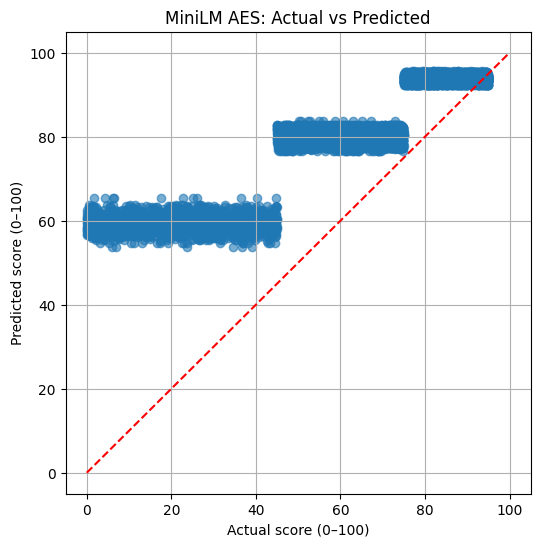

✅ Final model saved to: /content/drive/MyDrive/sbert_essay_model


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

trained_model = SentenceTransformer(output_path).to(device)

def cosine_to_01(a, b):
    cos = torch.nn.functional.cosine_similarity(a.unsqueeze(0), b.unsqueeze(0)).item()
    return (cos + 1.0) / 2.0

test_sentences1 = [ex.texts[0] for ex in test_examples]
test_sentences2 = [ex.texts[1] for ex in test_examples]
test_labels     = [ex.label for ex in test_examples]

preds = []
for s1, s2 in tqdm(zip(test_sentences1, test_sentences2), total=len(test_examples), desc="Evaluating"):
    emb1 = trained_model.encode(s1, convert_to_tensor=True)
    emb2 = trained_model.encode(s2, convert_to_tensor=True)
    preds.append(cosine_to_01(emb1, emb2))

y_true = np.array(test_labels)
y_pred = np.array(preds)

mse = mean_squared_error(y_true, y_pred)
mae = mean_absolute_error(y_true, y_pred)
r2  = r2_score(y_true, y_pred)
print(f"Test MSE: {mse:.4f} | MAE: {mae:.4f} | R2: {r2:.4f}")

# Plot hasil (skala 0–100)
plt.figure(figsize=(6,6))
plt.scatter(y_true*100, y_pred*100, alpha=0.6)
plt.plot([0,100],[0,100],'r--')
plt.xlabel("Actual score (0–100)")
plt.ylabel("Predicted score (0–100)")
plt.title("MiniLM AES: Actual vs Predicted")
plt.grid(True)
plt.show()

print("✅ Final model saved to:", output_path)

In [ ]:
print("Final model saved to:", output_path)


Final model saved to: /content/drive/MyDrive/sbert_essay_model
